# **Rate for cosine - SENSEI**

In [1]:
import pandas as pd
import numpy as np
from scipy import interpolate
from scipy import integrate
import matplotlib.pyplot as plt
from Atenuation import Atenuation_csv
from scipy.interpolate import interp1d
from scipy.integrate import simpson
custom_params = {
    'font.family': 'serif',
}

plt.rcParams.update(custom_params)
import os
cwd = os.getcwd() #os.path.dirname(os.getcwd())

## Atenuación a SENSEI

In [2]:
# Dataframes for the diferential fluxes
df_MD = pd.read_csv('Data/mCP_MD_differential_flux_surface.csv')
df_PB = pd.read_csv('Data/mCP_PB_differential_flux_surface.csv')


In [3]:
df_MD_a = Atenuation_csv(df_MD,2000)
df_PB_a = Atenuation_csv(df_PB,2000)

In [4]:
df_PB_a['m(GeV)'].unique()[35]

np.float64(0.1036356687550228)

In [5]:
df_PB_a['m(GeV)'].unique()==df_PB_a['m(GeV)'].unique()[30]

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False,  True, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False])

In [6]:
df_PB_a[df_PB_a['m(GeV)'] == 0.1]

,eps2,cos_theta,m(GeV),Energy(GeV),dphi_dEdCth(1/GeV/s/cm2/sr)


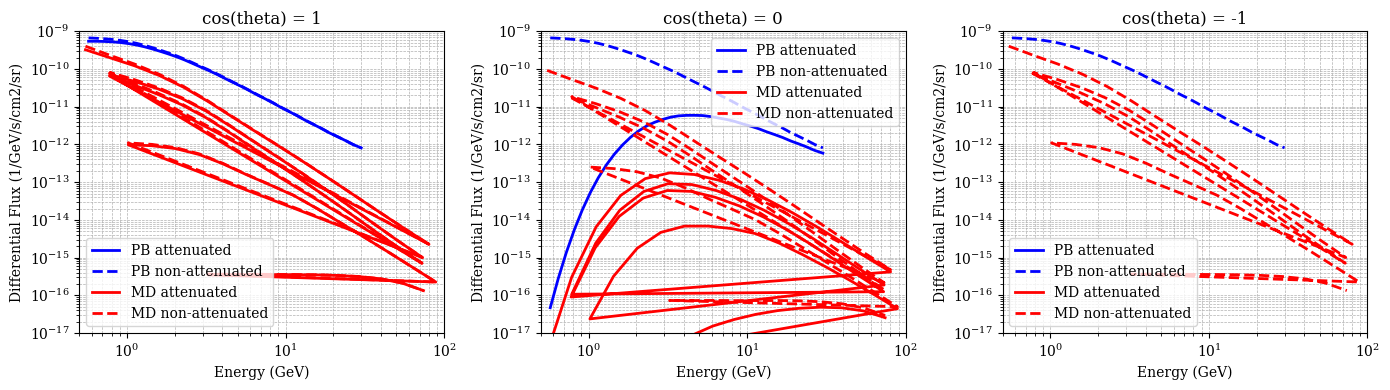

In [7]:
# Check the data to assure that its atenuated correctly

eps2 = 1e-4
cos_theta = [1,0,-1]
m_mcp = 0.1

fig, ax = plt.subplots(1,3,figsize=(14,4))
for i in range(len(cos_theta)):
    cos = cos_theta[i]
    PB_a = df_PB_a[(df_PB_a['eps2'] == eps2) & (df_PB_a['m(GeV)'] == df_PB_a['m(GeV)'].unique()[35]) & (df_PB_a['cos_theta']==cos)]
    PB_na = df_PB[(df_PB['eps2'] == eps2) & (df_PB['m(GeV)'] ==df_PB_a['m(GeV)'].unique()[35]) & (df_PB['cos_theta']==cos)]

    MD_a = df_MD_a[(df_MD_a['eps2'] == eps2) & (df_MD_a['m(GeV)'] == m_mcp) & (df_MD_a['cos_theta']==cos)]
    MD_na = df_MD[(df_MD['eps2'] == eps2) & (df_MD['m(GeV)'] == m_mcp) & (df_MD['cos_theta']==cos)]

    E_PB_a = PB_a['Energy(GeV)'].values
    E_PB_na = PB_na['Energy(GeV)'].values
    E_MD_a = MD_a['Energy(GeV)'].values
    E_MD_na = MD_na['Energy(GeV)'].values

    flux_PB = PB_a['dphi_dEdCth(1/GeV/s/cm2/sr)'].values
    flux_PB_na = PB_na['dphi_dEdCth(1/GeV/s/cm2/sr)'].values
    flux_MD_a = MD_a['dphi_dEdCth(1/GeV/s/cm2/sr)'].values
    flux_MD_na = MD_na['dphi_dEdCth(1/GeV/s/cm2/sr)'].values
    
    ax[i].plot(E_PB_a[E_PB_a>np.min(E_MD_a)], flux_PB[E_PB_a>np.min(E_MD_a)], label='PB attenuated', color='blue', linewidth=2)
    ax[i].plot(E_PB_na[E_PB_a>np.min(E_MD_a)], flux_PB_na[E_PB_a>np.min(E_MD_a)], label='PB non-attenuated', color='blue', linewidth=2, linestyle='dashed')
    ax[i].plot(E_MD_a[E_MD_a<1e2], flux_MD_a[E_MD_a<1e2], label='MD attenuated', color='red', linewidth=2)
    ax[i].plot(E_MD_na[E_MD_na<1e2], flux_MD_na[E_MD_na<1e2], label='MD non-attenuated', color='red', linewidth=2, linestyle='dashed')
    ax[i].set_xscale('log')
    ax[i].set_yscale('log')
    ax[i].set_xlabel('Energy (GeV)')
    ax[i].set_ylabel('Differential Flux (1/GeV/s/cm2/sr)')
    ax[i].set_title(f'cos(theta) = {cos}')
    ax[i].grid(True, which='both', linestyle='--', linewidth=0.5)
    ax[i].set_xlim([5e-1, 1e2])
    ax[i].set_ylim([1e-17, 1e-9])
    ax[i].legend()
plt.tight_layout()
plt.savefig('Figuras/attenuation_check.png', dpi=300, bbox_inches='tight')

In [8]:
df_MD_a.to_csv('Data/MCP_MD_differential_flux_attenuated_SENSEI.csv', index=False)
df_PB_a.to_csv('Data/MCP_PB_differential_flux_attenuated_SENSEI.csv', index=False)

## Rate esperado de eventos

In [9]:
df_MD_det = pd.read_csv('/home/lurishi/Escritorio/Doctorado/Heavenly_mCP/MCP_flux/MCP_MD_differential_flux_attenuated_SENSEI.csv')
df_PB_det = pd.read_csv('/home/lurishi/Escritorio/Doctorado/Heavenly_mCP/MCP_flux/MCP_PB_differential_flux_attenuated_SENSEI.csv')
df_det_sort_MD = (
    df_MD_det
    .sort_values(['cos_theta', 'm(GeV)'])
    .reset_index(drop=True)
)

df_det_sort_PB = (
    df_PB_det
    .sort_values(['cos_theta', 'm(GeV)'])
    .reset_index(drop=True)
)

In [10]:
# Defino las secciones eficaces por tipo de evento (de uno a 7 electrones)
df_sec_eficaz = pd.read_csv('Data/Data_Er/Seccion_eficaz_DEr_mCP.csv', sep=';')
Er = df_sec_eficaz['Er[eV]'].values # eV
# La tabla está calculada para eps2_ref = 1e-12; se reescala a epsilon = 1.
eps2_ref = 1
se_dif = df_sec_eficaz['sec_ef_dif[cm2/eV]'].values / eps2_ref # cm2/eV para epsilon = 1
# Importo la probabilidad de generar un evento de cada tipo

path = 'Data/Data_Er'
df_PC_1 = pd.read_csv(path+'/1e-.csv', sep=';')
df_PC_2 = pd.read_csv(path+'/2e-.csv', sep=';')
df_PC_3 = pd.read_csv(path+'/3e-.csv', sep=';')
df_PC_4 = pd.read_csv(path+'/4e-.csv', sep=';')
df_PC_5 = pd.read_csv(path+'/5e-.csv', sep=';')
df_PC_6 = pd.read_csv(path+'/6e-.csv', sep=';')
df_PC_7 = pd.read_csv(path+'/7e-.csv', sep=';')

Er_pc1, Er_pc2, Er_pc3, Er_pc4, Er_pc5, Er_pc6, Er_pc7 = df_PC_1[df_PC_1.columns[0]].values, df_PC_2[df_PC_2.columns[0]].values, df_PC_3[df_PC_3.columns[0]].values, df_PC_4[df_PC_4.columns[0]].values, df_PC_5[df_PC_5.columns[0]].values, df_PC_6[df_PC_6.columns[0]].values, df_PC_7[df_PC_7.columns[0]].values
P_PC_1, P_PC_2, P_PC_3, P_PC_4, P_PC_5, P_PC_6, P_PC_7 = df_PC_1[df_PC_1.columns[1]].values, df_PC_2[df_PC_2.columns[1]].values, df_PC_3[df_PC_3.columns[1]].values, df_PC_4[df_PC_4.columns[1]].values, df_PC_5[df_PC_5.columns[1]].values, df_PC_6[df_PC_6.columns[1]].values, df_PC_7[df_PC_7.columns[1]].values

Er_lista = [Er_pc1, Er_pc2, Er_pc3, Er_pc4, Er_pc5, Er_pc6, Er_pc7]
P_PC_lista = [P_PC_1, P_PC_2, P_PC_3, P_PC_4, P_PC_5, P_PC_6, P_PC_7]

In [11]:
E_min = 10 # eV
E_max = 20 # eV
E_common = np.linspace(E_min, E_max, 200) #eV
f_prob_pc_2 = interp1d(Er_pc2, P_PC_2, kind='linear', bounds_error=False, fill_value=0)
f_prob_pc_3 = interp1d(Er_pc3, P_PC_3, kind='linear', bounds_error=False, fill_value=0)
f_prob_pc_4 = interp1d(Er_pc4, P_PC_4, kind='linear', bounds_error=False, fill_value=0)
f_prob_pc_5 = interp1d(Er_pc5, P_PC_5, kind='linear', bounds_error=False, fill_value=0)
f_prob_pc_6 = interp1d(Er_pc6, P_PC_6, kind='linear', bounds_error=False, fill_value=0)
f_prob_pc_7 = interp1d(Er_pc7, P_PC_7, kind='linear', bounds_error=False, fill_value=0)

sec_eficaz = interp1d(Er, se_dif, kind='linear', bounds_error=False, fill_value=0)

sedif_2 = f_prob_pc_2(E_common) * sec_eficaz(E_common)
sedif_3 = f_prob_pc_3(E_common) * sec_eficaz(E_common)
sedif_4 = f_prob_pc_4(E_common) * sec_eficaz(E_common)
sedif_5 = f_prob_pc_5(E_common) * sec_eficaz(E_common)
sedif_6 = f_prob_pc_6(E_common) * sec_eficaz(E_common)
sedif_7 = f_prob_pc_7(E_common) * sec_eficaz(E_common)

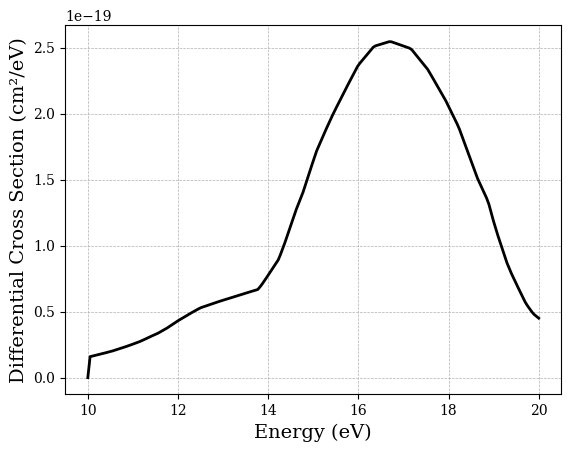

In [12]:
plt.plot(E_common, sec_eficaz(E_common), color='black', linewidth=2)
plt.xlabel('Energy (eV)',fontsize=14)
plt.ylabel('Differential Cross Section (cm²/eV)',fontsize=14)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)


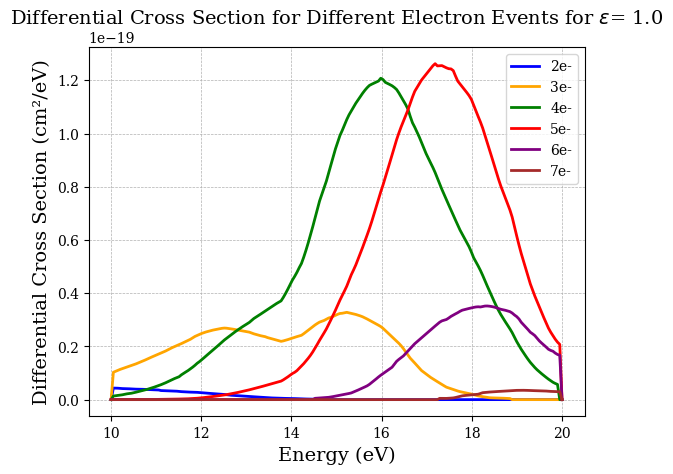

In [13]:
plt.plot(E_common, sedif_2, label='2e-', color='blue', linewidth=2)
plt.plot(E_common, sedif_3, label='3e-', color='orange', linewidth=2)
plt.plot(E_common, sedif_4, label='4e-', color='green', linewidth=2)
plt.plot(E_common, sedif_5, label='5e-', color='red', linewidth=2)
plt.plot(E_common, sedif_6, label='6e-', color='purple', linewidth=2)
plt.plot(E_common, sedif_7, label='7e-', color='brown', linewidth=2)
plt.xlabel('Energy (eV)',fontsize=14)
plt.ylabel(r'Differential Cross Section (cm²/eV)',fontsize=14)
plt.title(r'Differential Cross Section for Different Electron Events for $\varepsilon $= 1.0',fontsize=14)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.legend()

Para elegir los límites de integración uso la función de `Rate_for_cosine.py` `Er_max` que calcula la energía de recoil máxima que puede dejar una mCP que tiene una dada energía y una dada masa. Mi idea es chequear que no haya ninguna en los csv que caiga por debajo del máximo de nuestra sección eficaz, no debería ya que las mCP del csv están en GeV tanto en masa como en energía, pero bueno, hay que revisar :D 

$$Er_{max} = \frac{(E_{mcp}²-m_{mcp}^2)\cdot m_e}{m_{mcp}^2+2E_{mcp}\cdot m_e+m_e²}$$

No sé que onda las unidades de la masa, eso me genera dudas



In [14]:
me=0.000511 # electron mass in GeV
GeV_to_eV = 1e9 # Conversion factor from GeV to eV


def Er_max(E_MCP,m_MCP):
    return (E_MCP**2-m_MCP**2)*me/(m_MCP**2+2*E_MCP*me+me**2)

In [15]:
'''masses_MD = df_MD_det['m(GeV)'].unique()
energies_MD = df_MD_det['Energy(GeV)'].unique()
list = []
for m_MCP in masses_MD:
    for E_MCP in energies_MD:
        Er_max_value = Er_max(E_MCP, m_MCP)
        selected_flux = df_MD_det[
            (df_MD_det['m(GeV)'] == m_MCP)
            & (df_MD_det['Energy(GeV)'] == E_MCP)
        ]['dphi_dEdCth(1/GeV/s/cm2/sr)']
        if Er_max_value < 20 / GeV_to_eV and (selected_flux > 1e-40).any():
            print(f"m_MCP: {m_MCP}, E_MCP: {E_MCP}, Er_max: {Er_max_value * GeV_to_eV} eV")
            list.append((m_MCP, E_MCP, Er_max_value * GeV_to_eV))
if len(list) == 0:
    print("No hay combinaciones de m_MCP y E_MCP donde Er_max < 20 eV y selected_flux > 1e-40.")'''


'masses_MD = df_MD_det[\'m(GeV)\'].unique()\nenergies_MD = df_MD_det[\'Energy(GeV)\'].unique()\nlist = []\nfor m_MCP in masses_MD:\n    for E_MCP in energies_MD:\n        Er_max_value = Er_max(E_MCP, m_MCP)\n        selected_flux = df_MD_det[\n            (df_MD_det[\'m(GeV)\'] == m_MCP)\n            & (df_MD_det[\'Energy(GeV)\'] == E_MCP)\n        ][\'dphi_dEdCth(1/GeV/s/cm2/sr)\']\n        if Er_max_value < 20 / GeV_to_eV and (selected_flux > 1e-40).any():\n            print(f"m_MCP: {m_MCP}, E_MCP: {E_MCP}, Er_max: {Er_max_value * GeV_to_eV} eV")\n            list.append((m_MCP, E_MCP, Er_max_value * GeV_to_eV))\nif len(list) == 0:\n    print("No hay combinaciones de m_MCP y E_MCP donde Er_max < 20 eV y selected_flux > 1e-40.")'

Bueno, poniendo esa cota de que un flujo por debajo de eso es despreciable se ve que aquellas que no cumplen la condición tampoco llegan al detector... Así que todo bien :D. Integramos entonces en todo nuestro rango de energías, de 10 a 20 eV

In [16]:
# uso de referencia la función de rate for cosine, pero no depende de la energía de la mcp así que la cambién bastante
'''def XS(E,Ermin,eps2):
    # Input in GeV
    # Output in cm^2
    E_mcp=E
    Ermax=Er_max(E_mcp,m_tst)
    eps2_v=eps2
    I=integrate.quad(dsigma_dEr,Ermin,Ermax,args=(E_mcp,m_tst,eps2_v),epsabs=1e-10,epsrel=1e-10,limit=300)
    return I[0]*GeVM1_cm**2
'''

sigma_2 = simpson(sedif_2, E_common) # cm2 for epsilon = 1
sigma_3 = simpson(sedif_3, E_common) # cm2 for epsilon = 1
sigma_4 = simpson(sedif_4, E_common) # cm2 for epsilon = 1
sigma_5 = simpson(sedif_5, E_common) # cm2 for epsilon = 1
sigma_6 = simpson(sedif_6, E_common) # cm2 for epsilon = 1
sigma_7 = simpson(sedif_7, E_common) # cm2 for epsilon = 1

In [17]:
def Make_MCP(df_det_sort,cosine,eps2,m_tst):
    cos_v=cosine
    eps2_v=eps2
    df_fil=df_det_sort[df_det_sort['m(GeV)'] == m_tst]
    df_fil2=df_fil[df_fil['cos_theta'] == cos_v]
    df_fil3=df_fil2[df_fil2['eps2'] == eps2_v]
    return df_fil3

def MCP_flux(cosine,eps2,E):
    E_v=E
    cos_v=cosine
    eps2_v=eps2
    df=Make_MCP(cos_v,eps2_v)
    interpol=interpolate.interp1d(df['e'],df['flux'])
    return float(interpol(E_v))

In [18]:
# Calculemos el rate para un dado epsilon

eps2 = 1e-4#epsilon^2
Na = 6.022e23 # átomos/mol
A_Si = 28.0855 * 1e-3 # kg/mol
n_Si_ = Na / A_Si # átomos/kg
n_Si = 14*n_Si_  # átomos/kg
sec_eficaz_lista = [sigma_2*eps2, sigma_3*eps2, sigma_4*eps2, sigma_5*eps2, sigma_6*eps2, sigma_7*eps2] # cm2


In [19]:
# filtramos para el epsilon pedido

df_MD_fil = df_MD_det[df_MD_det['eps2'] == eps2]
df_PB_fil = df_PB_det[df_PB_det['eps2'] == eps2]


In [20]:
# Integro en coseno de theta para obtener el flujo diferencial en energía
def Flux_integrated_cosine(df_det_sort, m_tst, eps2):
    flux_column = 'dphi_dEdCth(1/GeV/s/cm2/sr)'
    df_flux = df_det_sort[
        (df_det_sort['m(GeV)'] == m_tst)
        & (df_det_sort['eps2'] == eps2)
    ]

    flux_grid = df_flux.pivot(
        index='Energy(GeV)',
        columns='cos_theta',
        values=flux_column,
    ).sort_index()
    flux_grid = flux_grid.sort_index(axis=1)

    if flux_grid.empty:
        raise ValueError(f'No hay flujo para m={m_tst}, eps2={eps2}')
    if flux_grid.isna().any().any():
        raise ValueError('Faltan valores de flujo para alguna energía o cos(theta)')

    cosines = flux_grid.columns.to_numpy()
    flux_integrated = 2 * np.pi * simpson(
        flux_grid.to_numpy(),
        x=cosines,
        axis=1,
    )

    return pd.DataFrame({
        'Energy(GeV)': flux_grid.index.to_numpy(),
        'dphi_dE(1/GeV/s/cm2)': flux_integrated,
    })


def Flux_integrated_energy(df_det_sort, m_tst, eps2):
    flux_integrated = Flux_integrated_cosine(df_det_sort, m_tst, eps2)
    energy = flux_integrated['Energy(GeV)'].to_numpy()
    flux = flux_integrated['dphi_dE(1/GeV/s/cm2)'].to_numpy()
    return simpson(flux, x=energy)


def Flux_integrated_energy_all_masses(df_det_sort, eps2_values):
    results = []
    masses = np.sort(df_det_sort['m(GeV)'].unique())

    for eps2 in eps2_values:
        for m_tst in masses:
            results.append({
                'm(GeV)': m_tst,
                'eps2': eps2,
                'Flux(1/s/cm2)': Flux_integrated_energy(
                    df_det_sort,
                    m_tst,
                    eps2,
                ),
            })

    return pd.DataFrame(results)


flux_energy_MD_all = Flux_integrated_energy_all_masses(
    df_det_sort_MD,
    eps2_values=[eps2],
)
flux_energy_PB_all = Flux_integrated_energy_all_masses(
    df_det_sort_PB,
    eps2_values=[eps2],
)
flux_energy_MD_all

,m(GeV),eps2,Flux(1/s/cm2)
0,0.010000,0.0001,4.428436e-08
1,0.010989,0.0001,3.236933e-08
2,0.012076,0.0001,2.952927e-08
3,0.013270,0.0001,2.673740e-08
4,0.014582,0.0001,2.399692e-08
...,...,...,...
71,0.900000,0.0001,1.118945e-13
72,0.950000,0.0001,1.105506e-13
73,1.000000,0.0001,1.087333e-13
74,1.300000,0.0001,8.676315e-14


In [21]:
# Multiplico por la sección eficaz n_Si y por el factor de conversión a rate diario (86400 s/día)
flux_energy_PB_all['rate 2 e(1/day/kg)'] = flux_energy_PB_all['Flux(1/s/cm2)'] * n_Si * sec_eficaz_lista[0]*86400  # 1/(day*kg)
flux_energy_PB_all['rate 3 e(1/day/kg)'] = flux_energy_PB_all['Flux(1/s/cm2)'] * n_Si * sec_eficaz_lista[1]*86400  # 1/(day*kg)
flux_energy_PB_all['rate 4 e(1/day/kg)'] = flux_energy_PB_all['Flux(1/s/cm2)'] * n_Si * sec_eficaz_lista[2]*86400  # 1/(day*kg)
flux_energy_PB_all['rate 5 e(1/day/kg)'] = flux_energy_PB_all['Flux(1/s/cm2)'] * n_Si * sec_eficaz_lista[3]*86400  # 1/(day*kg)
flux_energy_PB_all['rate 6 e(1/day/kg)'] = flux_energy_PB_all['Flux(1/s/cm2)'] * n_Si * sec_eficaz_lista[4]*86400  # 1/(day*kg)
flux_energy_PB_all['rate 7 e(1/day/kg)'] = flux_energy_PB_all['Flux(1/s/cm2)'] * n_Si * sec_eficaz_lista[5]*86400  # 1/(day*kg)
flux_energy_MD_all['rate 2 e(1/day/kg)'] = flux_energy_MD_all['Flux(1/s/cm2)'] * n_Si * sec_eficaz_lista[0]*86400  # 1/(day*kg)
flux_energy_MD_all['rate 3 e(1/day/kg)'] = flux_energy_MD_all['Flux(1/s/cm2)'] * n_Si * sec_eficaz_lista[1]*86400  # 1/(day*kg)
flux_energy_MD_all['rate 4 e(1/day/kg)'] = flux_energy_MD_all['Flux(1/s/cm2)'] * n_Si * sec_eficaz_lista[2]*86400  # 1/(day*kg)
flux_energy_MD_all['rate 5 e(1/day/kg)'] = flux_energy_MD_all['Flux(1/s/cm2)'] * n_Si * sec_eficaz_lista[3]*86400  # 1/(day*kg)
flux_energy_MD_all['rate 6 e(1/day/kg)'] = flux_energy_MD_all['Flux(1/s/cm2)'] * n_Si * sec_eficaz_lista[4]*86400  # 1/(day*kg)
flux_energy_MD_all['rate 7 e(1/day/kg)'] = flux_energy_MD_all['Flux(1/s/cm2)'] * n_Si * sec_eficaz_lista[5]*86400  # 1/(day*kg)


In [22]:
flux_energy_MD_all

,m(GeV),eps2,Flux(1/s/cm2),rate 2 e(1/day/kg),rate 3 e(1/day/kg),rate 4 e(1/day/kg),rate 5 e(1/day/kg),rate 6 e(1/day/kg),rate 7 e(1/day/kg)
0,0.010000,0.0001,4.428436e-08,1.129070,19.038923,54.984047,49.680675,12.485360,7.777312e-01
1,0.010989,0.0001,3.236933e-08,0.825285,13.916362,40.190188,36.313727,9.126083,5.684769e-01
2,0.012076,0.0001,2.952927e-08,0.752875,12.695349,36.663928,33.127585,8.325366,5.185991e-01
3,0.013270,0.0001,2.673740e-08,0.681694,11.495057,33.197507,29.995510,7.538238,4.695678e-01
4,0.014582,0.0001,2.399692e-08,0.611823,10.316859,29.794894,26.921090,6.765598,4.214389e-01
...,...,...,...,...,...,...,...,...,...
71,0.900000,0.0001,1.118945e-13,0.000003,0.000048,0.000139,0.000126,0.000032,1.965114e-06
72,0.950000,0.0001,1.105506e-13,0.000003,0.000048,0.000137,0.000124,0.000031,1.941513e-06
73,1.000000,0.0001,1.087333e-13,0.000003,0.000047,0.000135,0.000122,0.000031,1.909597e-06
74,1.300000,0.0001,8.676315e-14,0.000002,0.000037,0.000108,0.000097,0.000024,1.523752e-06


In [23]:
flux_energy_PB_all

,m(GeV),eps2,Flux(1/s/cm2),rate 2 e(1/day/kg),rate 3 e(1/day/kg),rate 4 e(1/day/kg),rate 5 e(1/day/kg),rate 6 e(1/day/kg),rate 7 e(1/day/kg)
0,0.010000,0.0001,6.297087e-09,1.605499e-01,2.707270e+00,7.818546e+00,7.064424e+00,1.775376e+00,1.105907e-01
1,0.010691,0.0001,6.301548e-09,1.606636e-01,2.709188e+00,7.824085e+00,7.069429e+00,1.776634e+00,1.106691e-01
2,0.011430,0.0001,6.304907e-09,1.607493e-01,2.710633e+00,7.828256e+00,7.073198e+00,1.777581e+00,1.107281e-01
3,0.012219,0.0001,6.294029e-09,1.604719e-01,2.705956e+00,7.814749e+00,7.060994e+00,1.774514e+00,1.105370e-01
4,0.013063,0.0001,6.315573e-09,1.610212e-01,2.715218e+00,7.841498e+00,7.085163e+00,1.780588e+00,1.109154e-01
...,...,...,...,...,...,...,...,...,...
71,1.148241,0.0001,3.706512e-17,9.450087e-10,1.593520e-08,4.602055e-08,4.158173e-08,1.045000e-08,6.509454e-10
72,1.227574,0.0001,1.410952e-17,3.597350e-10,6.066027e-09,1.751857e-08,1.582885e-08,3.977984e-09,2.477944e-10
73,1.312388,0.0001,5.406196e-18,1.378358e-10,2.324255e-09,6.712404e-09,6.064973e-09,1.524202e-09,9.494473e-11
74,1.403062,0.0001,2.075459e-18,5.291569e-11,8.922902e-10,2.576917e-09,2.328366e-09,5.851468e-10,3.644964e-11


# **Momento de sacar límites**

In [24]:
from scipy.stats import chi2

In [25]:
eventos = np.array([0,0,0,0,0,0]) # sin eventos observados para 2,3,4,5,6,7 electrones

In [26]:
p_on_the_left = 1 - 0.9
degrees_of_freedom = 2 * (eventos + 1)
x = chi2.ppf(1 - p_on_the_left, degrees_of_freedom)
mu_ul = x / 2
print(mu_ul)

[2.30258509 2.30258509 2.30258509 2.30258509 2.30258509 2.30258509]


In [27]:
rates_exp = mu_ul / 1
rates_exp

array([2.30258509, 2.30258509, 2.30258509, 2.30258509, 2.30258509,
       2.30258509])

In [28]:
def limites_exclusion(r_exp, df, sigma,ne):
   if ne < 1 or ne > 10:
       raise ValueError("ne debe estar entre 1 y 10")
   if not isinstance(ne, int):
       raise TypeError("ne debe ser un entero")
   if sigma <= 0:
       raise ValueError("La sección eficaz del dataframe debe ser un número positivo")
  
   r_teo = np.array(df[f'rate {ne} e(1/day/kg)'])
   sigma_exp = ((r_exp/r_teo)**(1/2))*sigma
  
   return sigma_exp

In [29]:
eps_pb = np.zeros((len(rates_exp),len(flux_energy_PB_all)))
eps_md = np.zeros((len(rates_exp),len(flux_energy_MD_all)))
for i in range(len(rates_exp)):
    eps_pb_ = limites_exclusion(rates_exp[i], flux_energy_PB_all, eps2, i+2)
    eps_md_ = limites_exclusion(rates_exp[i], flux_energy_MD_all, eps2, i+2)
    eps_pb[i, :] = eps_pb_
    eps_md[i, :] = eps_md_

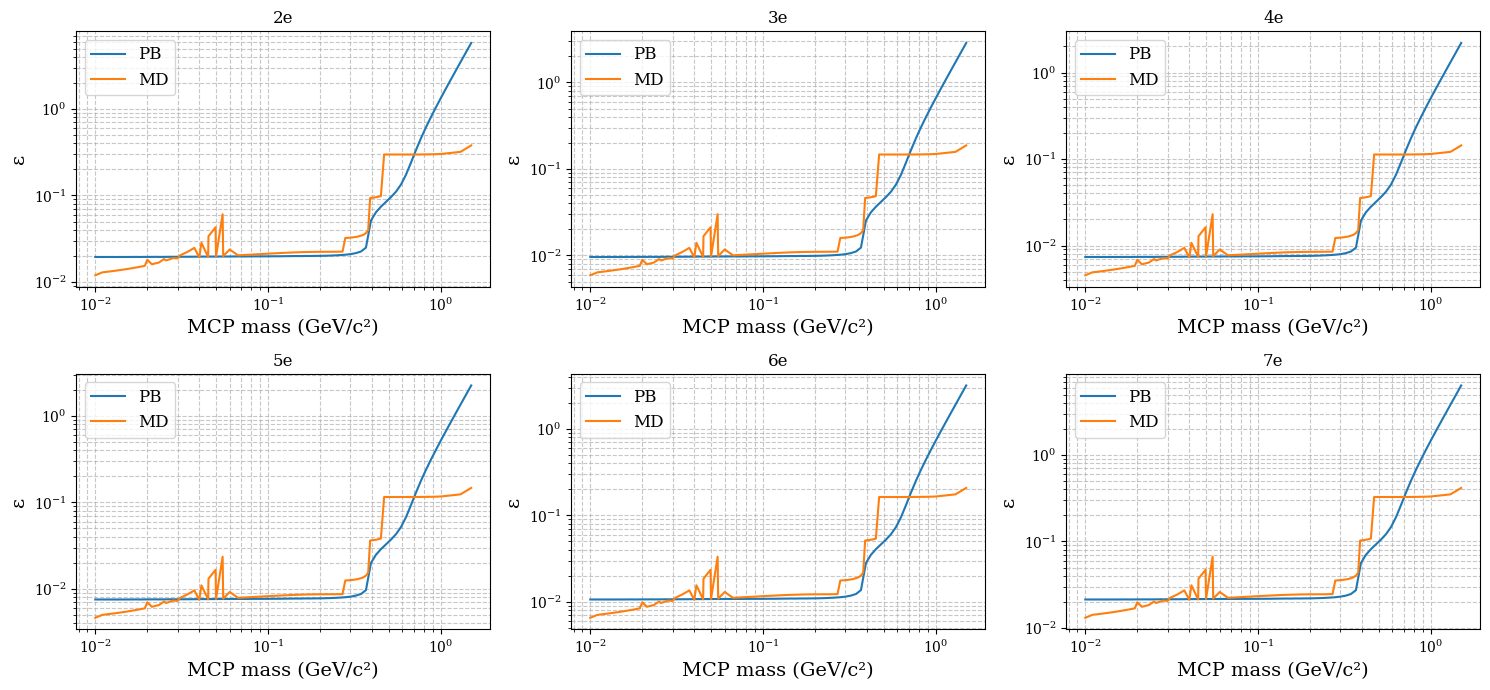

In [30]:
fig, ax = plt.subplots(2,3, figsize=(15, 7))
ax[0,0].plot(flux_energy_PB_all[flux_energy_PB_all.columns[0]], np.sqrt(eps_pb[0,:]), label='PB')
ax[0,0].plot(flux_energy_MD_all[flux_energy_MD_all.columns[0]], np.sqrt(eps_md[0,:]), label='MD')
ax[0,0].set_title('2e')
ax[0,0].set_xscale('log')
ax[0,0].set_yscale('log')
ax[0,0].set_xlabel('MCP mass (GeV/c²)', fontsize=14)
ax[0,0].set_ylabel('ε', fontsize=14)
ax[0,0].grid(linestyle='--', which='both', alpha=0.7)
ax[0,0].legend(fontsize=12)
# 3e
ax[0,1].plot(flux_energy_PB_all[flux_energy_PB_all.columns[0]], np.sqrt(eps_pb[1,:]), label='PB')
ax[0,1].plot(flux_energy_MD_all[flux_energy_MD_all.columns[0]], np.sqrt(eps_md[1,:]), label='MD')
ax[0,1].set_title('3e')
ax[0,1].set_xscale('log')
ax[0,1].set_yscale('log')
ax[0,1].set_xlabel('MCP mass (GeV/c²)', fontsize=14)
ax[0,1].set_ylabel('ε', fontsize=14)
ax[0,1].grid(linestyle='--', which='both', alpha=0.7)
ax[0,1].legend(fontsize=12)
# 4e
ax[0,2].plot(flux_energy_PB_all[flux_energy_PB_all.columns[0]], np.sqrt(eps_pb[2,:]), label='PB')
ax[0,2].plot(flux_energy_MD_all[flux_energy_MD_all.columns[0]], np.sqrt(eps_md[2,:]), label='MD')
ax[0,2].set_title('4e')
ax[0,2].set_xscale('log')
ax[0,2].set_yscale('log')
ax[0,2].set_xlabel('MCP mass (GeV/c²)', fontsize=14)
ax[0,2].set_ylabel('ε',fontsize=14)
ax[0,2].grid(linestyle='--', which='both', alpha=0.7)
ax[0,2].legend(fontsize=12)
# 5e
ax[1,0].plot(flux_energy_PB_all[flux_energy_PB_all.columns[0]], np.sqrt(eps_pb[3,:]), label='PB')
ax[1,0].plot(flux_energy_MD_all[flux_energy_MD_all.columns[0]], np.sqrt(eps_md[3,:]), label='MD')
ax[1,0].set_title('5e')
ax[1,0].set_xscale('log')
ax[1,0].set_yscale('log')
ax[1,0].set_xlabel('MCP mass (GeV/c²)', fontsize=14)
ax[1,0].set_ylabel('ε',fontsize=14)
ax[1,0].grid(linestyle='--', which='both', alpha=0.7)
ax[1,0].legend(fontsize=12)
# 6e
ax[1,1].plot(flux_energy_PB_all[flux_energy_PB_all.columns[0]], np.sqrt(eps_pb[4,:]), label='PB')
ax[1,1].plot(flux_energy_MD_all[flux_energy_MD_all.columns[0]], np.sqrt(eps_md[4,:]), label='MD')
ax[1,1].set_title('6e')
ax[1,1].set_xscale('log')
ax[1,1].set_yscale('log')
ax[1,1].set_xlabel('MCP mass (GeV/c²)', fontsize=14)
ax[1,1].set_ylabel('ε',fontsize=14)
ax[1,1].grid(linestyle='--', which='both', alpha=0.7)
ax[1,1].legend(fontsize=12)
# 7e
ax[1,2].plot(flux_energy_PB_all[flux_energy_PB_all.columns[0]], np.sqrt(eps_pb[5,:]), label='PB')
ax[1,2].plot(flux_energy_MD_all[flux_energy_MD_all.columns[0]], np.sqrt(eps_md[5,:]), label='MD')
ax[1,2].set_title('7e')
ax[1,2].set_xscale('log')
ax[1,2].set_yscale('log')
ax[1,2].set_xlabel('MCP mass (GeV/c²)', fontsize=14)
ax[1,2].set_ylabel('ε',fontsize=14)
ax[1,2].grid(linestyle='--', which='both', alpha=0.7)
ax[1,2].legend(fontsize=12)
plt.tight_layout()
plt.savefig('Figuras/Limites_mCP_SENSEI.png', dpi=300)